In [32]:
# 1. IMPORT LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)


# ============================================
# 2. CONFIGURATION
# sunject to change if we use mine or others dataset separately (pls delete this comment later nga)
# ============================================

CSV_FILE = "planets_300.csv"

A_COL = "a_AU"
M_COL = "M_star_solar"
T_COL = "T_years"

In [30]:
df = pd.read_csv(CSV_FILE)

print("First five rows:")
print(df.head())

print("\nDataset information:")
print(df.info())

First five rows:
  planet_id       a_AU  M_star_solar  T_true_years  noise_fraction     T_years
0      P001  23.229984      1.278996     99.000800        0.037438  102.707241
1      P002  13.194409      0.634552     60.166015       -0.007576   59.710226
2      P003  25.765008      1.036068    128.484659        0.010904  129.885609
3      P004  20.936172      1.014223     95.121619       -0.072298   88.244548
4      P005   2.870612      1.357572      4.174267       -0.034690    4.029460

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   planet_id       300 non-null    object 
 1   a_AU            300 non-null    float64
 2   M_star_solar    300 non-null    float64
 3   T_true_years    300 non-null    float64
 4   noise_fraction  300 non-null    float64
 5   T_years         300 non-null    float64
dtypes: float64(5), obj

In [31]:
# Keep only the required columns
df = df[[A_COL, M_COL, T_COL]].copy()

# Convert columns to numerical values
for col in [A_COL, M_COL, T_COL]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove missing values
df = df.dropna()

# Remove non-positive values
df = df[
    (df[A_COL] > 0) &
    (df[M_COL] > 0) &
    (df[T_COL] > 0)
].copy()

print("\nNumber of valid planets:", len(df))

# Wee did this cuz logarithms are only defined for positive numbers.

#We also remove missing values.

#This is called data preprocessing.


Number of valid planets: 300


In [ ]:
#LOGARITHMIC TRANSFORMATION
df["log_a"] = np.log10(df["a_AU"])

df["log_M"] = np.log10(df["M_star_solar"])

df["log_T"] = np.log10(df["T_years"])

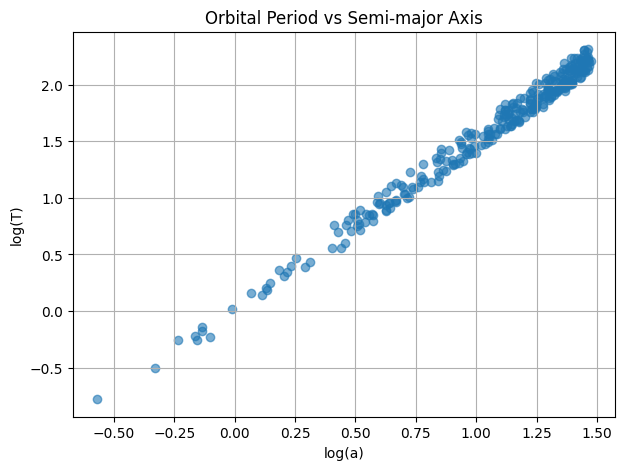

In [ ]:
plt.figure(figsize=(7, 5))

plt.scatter(df["log_a"], df["log_T"], alpha=0.6)

plt.xlabel("log(a)")
plt.ylabel("log(T)")
plt.title("Orbital Period vs Semi-major Axis")

plt.grid()
plt.show()

Training the linear regression model (the actual ML chigaga)

In [ ]:
# 6. EXTRAPOLATION DATA SPLIT
# ============================================

# Training: planets with a < 1 AU
train_data = df[df[A_COL] < 1].copy()

# Testing: planets with a > 1 AU
test_data = df[df[A_COL] > 1].copy()

print("\nEXTRAPOLATION DATA SPLIT")

print("Training planets (a < 1 AU):",
      len(train_data))

print("Testing planets (a > 1 AU):",
      len(test_data))

if len(train_data) < 3:
    raise ValueError(
        "Too few training planets. Check the dataset."
    )

if len(test_data) < 2:
    raise ValueError(
        "Too few testing planets to evaluate."
    )





EXTRAPOLATION DATA SPLIT
Training planets (a < 1 AU): 9
Testing planets (a > 1 AU): 291


In [ ]:
## 7. SELECT FEATURES AND TARGET
# ============================================

# Independent variables
X_train = train_data[["log_a", "log_M"]]

X_test = test_data[["log_a", "log_M"]]

# Dependent variable
y_train = train_data["log_T"]

y_test = test_data["log_T"]

#X: Independent variables, also called features. y: Dependent variable, also called target
#Our model is y = b0 + b1*x1 + b2*x2
#It will use the two features to predict the target.


In [ ]:
# ============================================
# 8. TRAIN LINEAR REGRESSION MODEL
# ============================================

model = LinearRegression()

model.fit(X_train, y_train)

print("\nMODEL TRAINED SUCCESSFULLY")


MODEL TRAINED SUCCESSFULLY


In [ ]:
# ============================================
# 9. PREDICT TEST DATA
# ============================================

y_pred = model.predict(X_test)



In [ ]:
# 10. DISPLAY REGRESSION COEFFICIENTS
# ============================================

intercept = model.intercept_

beta_a, beta_M = model.coef_

print("\nREGRESSION COEFFICIENTS")

print("Intercept:", intercept)

print("Coefficient of log(a):", beta_a)

print("Coefficient of log(M):", beta_M)

print("\nRegression equation:")

print(
    f"log(T) = {intercept:.4f}"
    f" + ({beta_a:.4f}) log(a)"
    f" + ({beta_M:.4f}) log(M)"
)


REGRESSION COEFFICIENTS
Intercept: 0.007552896822527244
Coefficient of log(a): 1.5132906231185745
Coefficient of log(M): -0.44539589500389826

Regression equation:
log(T) = 0.0076 + (1.5133) log(a) + (-0.4454) log(M)


In [ ]:
# 11. EVALUATE EXTRAPOLATION PERFORMANCE
# ============================================

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

mae = mean_absolute_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)

print("\nEXTRAPOLATION PERFORMANCE")

print("Mean Squared Error:", mse)

print("Root Mean Squared Error:", rmse)

print("Mean Absolute Error:", mae)

print("R-squared:", r2)


EXTRAPOLATION PERFORMANCE
Mean Squared Error: 0.0007633247574528695
Root Mean Squared Error: 0.027628332513071965
Mean Absolute Error: 0.02325081643409346
R-squared: 0.9970942912140919


In [ ]:
# 12. COMPARE WITH KEPLER'S THEORETICAL LAW
# ============================================

comparison = pd.DataFrame({
    "Parameter": ["log(a)", "log(M)"],
    "Theoretical": [1.5, -0.5],
    "Fitted": [beta_a, beta_M]
})

comparison["Absolute Error"] = abs(
    comparison["Fitted"] -
    comparison["Theoretical"]
)

print("\nTHEORETICAL VS FITTED COEFFICIENTS")

print(comparison.to_string(index=False))


THEORETICAL VS FITTED COEFFICIENTS
Parameter  Theoretical    Fitted  Absolute Error
   log(a)          1.5  1.513291        0.013291
   log(M)         -0.5 -0.445396        0.054604


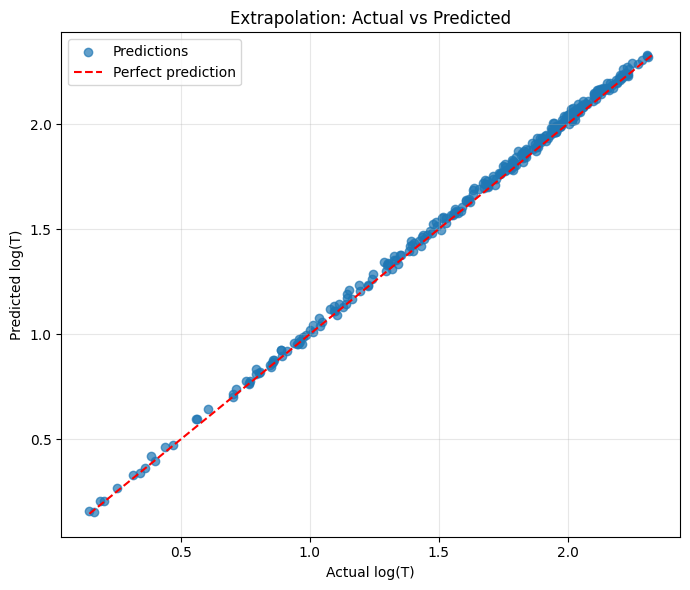

In [ ]:
# 13. ACTUAL VS PREDICTED GRAPH
# ============================================

plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.7,
    label="Predictions"
)

limits = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]

plt.plot(
    limits,
    limits,
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual log(T)")
plt.ylabel("Predicted log(T)")

plt.title("Extrapolation: Actual vs Predicted")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig("extrapolation_predictions.png", dpi=300)

plt.show()